# Árboles de decisión explicados fácil
**Diseño de Soluciones de Inteligencia Artificial (CERTUS) · Sesión 5 · Tema 8**

> **Cómo usar este cuaderno:** ejecuta las celdas de arriba hacia abajo (▶ o `Shift + Enter`). Lee el texto, mira el gráfico y compara. Lo importante es **entender qué hace cada parámetro** y cómo se nota en el resultado.

## ¿Qué vas a aprender?
1. Qué es un árbol de decisión (como el juego de las "20 preguntas").
2. Cómo decide dónde cortar (**impureza Gini**), con un cálculo a mano.
3. Los **parámetros** principales: `max_depth`, `min_samples_leaf`, `min_samples_split`, `criterion`, `max_features`, `ccp_alpha`, `class_weight`...
4. Cómo un árbol se **sobreajusta** y cómo frenarlo.
5. Cómo ver e interpretar las reglas del árbol y qué variables importan.
6. De un árbol a un **bosque aleatorio** (varios árboles votando).

### Palabras que vas a ver
| Palabra | Significado fácil |
|---|---|
| **Nodo** | Una pregunta del árbol (ej.: "¿llamó a soporte más de 2 veces?"). |
| **Hoja** | Un final del árbol: ahí se da la respuesta ("se va" / "se queda"). |
| **Profundidad** | Cuántas preguntas seguidas se hacen como máximo. |
| **Impureza** | Qué tan "mezclado" está un grupo. 0 = todos iguales (puro). |
| **Hiperparámetro** | Una perilla que tú configuras antes de entrenar. |

## 0. Preparación (ejecuta esta celda primero)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEMILLA = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def frontera(modelo, X, y, ax=None, titulo=""):
    # Dibuja la 'frontera de decisión' de un modelo entrenado con 2 variables:
    # el fondo rojo/azul muestra qué predice el modelo en cada punto del plano.
    ax = ax or plt.gca()
    modelo.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return modelo


def metricas(modelo, Xv, yv):
    # Calcula las métricas principales de un modelo ya entrenado.
    pred = modelo.predict(Xv)
    if hasattr(modelo, "predict_proba"):
        puntaje = modelo.predict_proba(Xv)[:, 1]
    else:
        puntaje = modelo.decision_function(Xv)
    return pd.Series({
        "exactitud": accuracy_score(yv, pred),
        "precisión": precision_score(yv, pred, zero_division=0),
        "recall": recall_score(yv, pred),
        "F1": f1_score(yv, pred),
        "AUC": roc_auc_score(yv, puntaje),
    }).round(3)

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text

## 1. La idea: el juego de las 20 preguntas
Un árbol de decisión aprende una **cadena de preguntas de sí/no** que va separando a los clientes en grupos cada vez más parecidos entre sí. Ejemplo (inventado):

```
¿Llamó a soporte 3 o más veces?
 ├─ Sí → ¿Su satisfacción es menor a 3?
 │        ├─ Sí → SE VA (80 %)
 │        └─ No → se queda (60 %)
 └─ No → se queda (90 %)
```

Ventajas: **se lee como reglas de negocio**, no necesita escalar variables, capta relaciones que no son rectas y acepta variables mezcladas. Desventaja principal: **se sobreajusta con facilidad** (si lo dejas crecer, memoriza).

### ¿Cómo decide dónde cortar? La impureza de Gini
En cada nodo prueba muchas preguntas posibles y elige la que **deja los grupos más "puros"**. La impureza Gini de un grupo con proporción `p` de "se va" es:

**Gini = 1 − p² − (1 − p)²**

* Grupo 50 %-50 % → Gini = 0,50 (máximo desorden).
* Grupo 100 % de un solo tipo → Gini = 0 (puro).

Calculémoslo con un ejemplo a mano:

In [2]:
def gini(p):
    return 1 - p**2 - (1 - p)**2

# Grupo inicial: 100 clientes, 30 se fueron y 70 se quedaron
print("Gini del grupo inicial (30% se va):", round(gini(0.30), 3))

# Pregunta candidata: "¿llamó a soporte 3 o más veces?"
#   SI: 40 clientes, 28 se fueron (70%)   NO: 60 clientes, 2 se fueron (3,3%)
g_si, g_no = gini(28 / 40), gini(2 / 60)
gini_despues = (40 / 100) * g_si + (60 / 100) * g_no      # promedio ponderado por tamaño
print("Gini del grupo SI :", round(g_si, 3))
print("Gini del grupo NO :", round(g_no, 3))
print("Gini promedio tras la pregunta:", round(gini_despues, 3))
print("Mejora (ganancia):", round(gini(0.30) - gini_despues, 3), "<- el árbol elige la pregunta con MAYOR mejora")

Gini del grupo inicial (30% se va): 0.42
Gini del grupo SI : 0.42
Gini del grupo NO : 0.064
Gini promedio tras la pregunta: 0.207
Mejora (ganancia): 0.213 <- el árbol elige la pregunta con MAYOR mejora


La pregunta redujo la impureza de 0,42 a ~0,21: **es una buena pregunta**. El árbol repite este proceso en cada nodo, con cada variable y cada punto de corte posible, y se queda con el mejor. (Con `criterion="entropy"` usa otra fórmula de desorden, pero el resultado casi siempre es parecido.)

## Preparar los datos reales (caso operadora móvil)
Usamos el mismo archivo de las semanas 3 y 4: `clientes_telecom.csv`. Queremos predecir `se_fue` (1 = el cliente se fue, 0 = se quedó).

Aquí solo hacemos lo indispensable: limpieza mínima, separar una parte para **validar** y convertir las columnas a números (rellenar vacíos, escalar y pasar categorías a 0/1). Si no entiendes esta celda, no importa: **ejecútala tal cual** y sigue.

In [3]:
# Cargamos el archivo desde el repositorio del curso.
# Si no hay internet, sube clientes_telecom.csv al panel de archivos de Colab y cambia URL por "clientes_telecom.csv".
URL = "https://raw.githubusercontent.com/jeanpier22/Diseno-de-Soluciones-de-Inteligencia-Artificial/main/Practica_Semana3y4/clientes_telecom.csv"
df = pd.read_csv(URL, encoding="utf-8-sig")

# Limpieza mínima (la misma de la Sesión 5)
df = df.drop_duplicates(subset="id_cliente").copy()
df.loc[(df["edad"] < 14) | (df["edad"] > 100), "edad"] = np.nan
df.loc[df["monto_factura"] < 0, "monto_factura"] = np.nan
df["tipo_plan"] = (df["tipo_plan"].str.lower().str.replace("-", "", regex=False)
                   .replace({"prepago": "Prepago", "postpago ilimitado": "Postpago Ilimitado", "postpago básico": "Postpago Básico"}))

num = ["edad", "consumo_datos_mb", "minutos_llamadas", "recargas_mes", "monto_factura",
       "velocidad_mbps", "caidas_red_mes", "llamadas_soporte", "satisfaccion"]
cat = ["tipo_plan", "metodo_pago", "departamento"]

train = df[df["particion"] == "train"]
X_train, y_train = train[num + cat], train["se_fue"]

# Del 'train' separamos una parte para VALIDAR (examen de práctica). El 'test' no se toca en este cuaderno.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
], sparse_threshold=0)

Xp_tr = prep.fit_transform(X_tr)      # se 'aprende' solo con entrenamiento
Xp_val = prep.transform(X_val)
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print("Clientes para entrenar:", Xp_tr.shape[0], "| para validar:", Xp_val.shape[0], "| columnas:", Xp_tr.shape[1])
print("Proporción que se va:", round(y_tr.mean(), 3))

Clientes para entrenar: 900 | para validar: 300 | columnas: 31
Proporción que se va: 0.288


## 2. Nuestro primer árbol (pequeño y legible)
Entrenamos un árbol con **solo 2 niveles de profundidad** para poder verlo entero. Cada caja muestra: la pregunta, la impureza (`gini`), cuántos clientes (`samples`), cuántos hay de cada clase (`value = [se quedan, se van]`) y la clase mayoritaria.

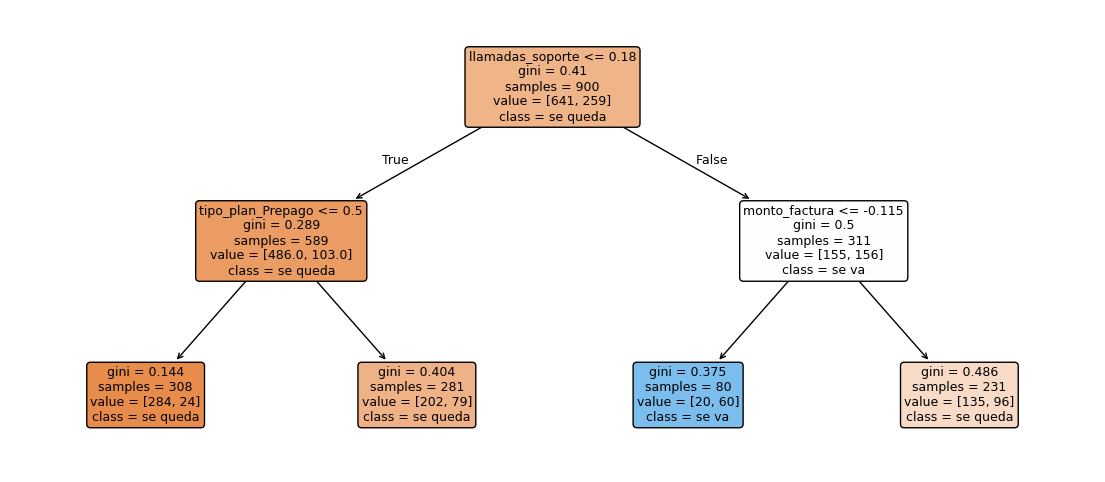

In [4]:
arbol = DecisionTreeClassifier(max_depth=2, random_state=SEMILLA)
arbol.fit(Xp_tr, y_tr)

plt.figure(figsize=(14, 6))
plot_tree(arbol, feature_names=nombres, class_names=["se queda", "se va"], filled=True, rounded=True, fontsize=9)
plt.show()

**Cómo leerlo:** empieza arriba. Si la respuesta a la pregunta es **verdadera** vas a la izquierda; si es **falsa**, a la derecha. Al llegar a una caja sin preguntas (hoja) lees la predicción. Los colores: naranja = mayoría "se queda", azul = mayoría "se va"; cuanto más intenso, más puro.

> **Ojo:** los números de las preguntas (por ejemplo `llamadas_soporte <= 0.18`) están **escalados** (son desviaciones estándar), no son llamadas reales. Para ver valores reales habría que entrenar sin escalar; para árboles el escalado es opcional.

Lo mismo, en forma de **reglas de texto** (muy útil para documentar):

In [5]:
print(export_text(arbol, feature_names=nombres))

|--- llamadas_soporte <= 0.18
|   |--- tipo_plan_Prepago <= 0.50
|   |   |--- class: 0
|   |--- tipo_plan_Prepago >  0.50
|   |   |--- class: 0
|--- llamadas_soporte >  0.18
|   |--- monto_factura <= -0.11
|   |   |--- class: 1
|   |--- monto_factura >  -0.11
|   |   |--- class: 0



## 3. Los parámetros del árbol (las "perillas")
| Parámetro | Qué hace en palabras simples | Por defecto | Qué pasa si lo cambias |
|---|---|---|---|
| **`max_depth`** | **Máximo de preguntas seguidas.** | `None` (sin límite) | **Poco** (1-3): árbol simple, puede quedarse corto (*underfitting*). **Mucho / `None`**: memoriza los datos (*overfitting*). Es la perilla más importante. |
| **`min_samples_leaf`** | Mínimo de clientes que debe tener cada hoja. | `1` | Súbelo (10, 30) para que no existan hojas con 1-2 clientes: **hace el árbol más estable y general**. |
| **`min_samples_split`** | Mínimo de clientes que debe tener un nodo para poder dividirse. | `2` | Súbelo para evitar divisiones sobre grupos pequeños. Hace un efecto parecido al anterior. |
| **`max_leaf_nodes`** | Máximo de hojas totales. | `None` | Limita directamente el tamaño del árbol. |
| **`criterion`** | La fórmula para medir impureza: `"gini"` o `"entropy"`. | `"gini"` | Casi no cambia el resultado. Se puede probar. |
| **`max_features`** | Cuántas variables mira en cada corte. | `None` (todas) | Menos variables = árbol más "distinto" y menos sobreajustado. Es la base de los bosques aleatorios. |
| **`ccp_alpha`** | **Poda**: castiga árboles grandes y corta ramas que aportan poco. | `0.0` | Súbelo un poco (0,001–0,02) para podar ramas inútiles. |
| **`class_weight`** | Qué tan caro es fallar en cada clase. | `None` | `"balanced"` → mejora el recall de la clase minoritaria (los que se van). |
| **`splitter`** | `"best"` busca el mejor corte; `"random"` prueba cortes al azar. | `"best"` | Casi nunca se toca. |
| **`random_state`** | Semilla para repetir resultados. | `None` | Fíjala (42). |

> **Regla práctica:** si solo vas a ajustar una perilla, que sea **`max_depth`**; si vas a ajustar dos, añade **`min_samples_leaf`**.

### Experimento A · `max_depth`: ¿cuántas preguntas conviene?
Vamos a entrenar árboles de profundidad 1 a 15 y comparar la nota en **entrenamiento** vs. **validación** (AUC).

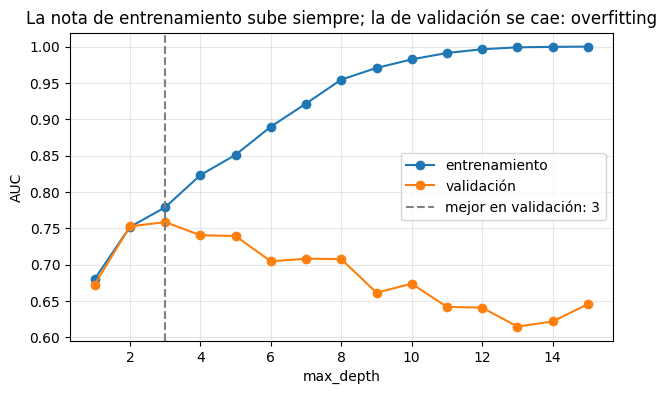

Mejor profundidad según validación: 3


In [6]:
profundidades = range(1, 16)
auc_tr, auc_val = [], []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(Xp_tr, y_tr)
    auc_tr.append(roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]))
    auc_val.append(roc_auc_score(y_val, m.predict_proba(Xp_val)[:, 1]))

plt.plot(profundidades, auc_tr, "o-", label="entrenamiento")
plt.plot(profundidades, auc_val, "o-", label="validación")
mejor = list(profundidades)[int(np.argmax(auc_val))]
plt.axvline(mejor, color="gray", ls="--", label=f"mejor en validación: {mejor}")
plt.xlabel("max_depth"); plt.ylabel("AUC"); plt.legend()
plt.title("La nota de entrenamiento sube siempre; la de validación se cae: overfitting")
plt.show()
print("Mejor profundidad según validación:", mejor)

**Cómo leerlo:** la nota en entrenamiento llega casi a 1,0 (el árbol **memorizó** a los clientes). La de validación sube un poquito y luego **cae**. La distancia entre ambas curvas es el **overfitting**. Elegimos la profundidad donde la validación es máxima.

### Experimento B · Ver el overfitting en un dibujo (datos en 2D)
Usamos dos variables inventadas (`make_moons`: dos medias lunas entrelazadas, con ruido) para **ver** cómo el árbol divide el plano. Compara tres profundidades:

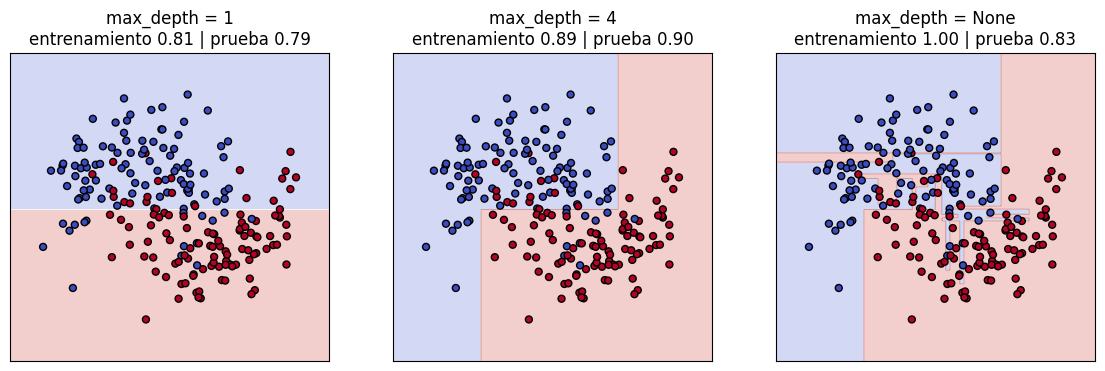

In [7]:
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=3)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0)

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, d in zip(ejes, [1, 4, None]):
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    frontera(m, Xm_tr, ym_tr, ax, "")
    ax.set_title(f"max_depth = {d}\nentrenamiento {m.score(Xm_tr, ym_tr):.2f} | prueba {m.score(Xm_te, ym_te):.2f}")
plt.show()

* **`max_depth=1`**: un solo corte; frontera demasiado simple (*underfitting*).
* **`max_depth=4`**: la frontera sigue la forma general sin obsesionarse con puntos sueltos (**punto justo**).
* **`max_depth=None`**: se arma un "mosaico" que rodea cada punto, incluso los que son ruido (*overfitting*: entrenamiento ~1,00, prueba menor).

### Experimento C · `min_samples_leaf`: hojas con "mínimo de gente"
Con `max_depth` libre, pero obligando a que cada hoja tenga cierto mínimo de clientes, el árbol deja de memorizar casos aislados.

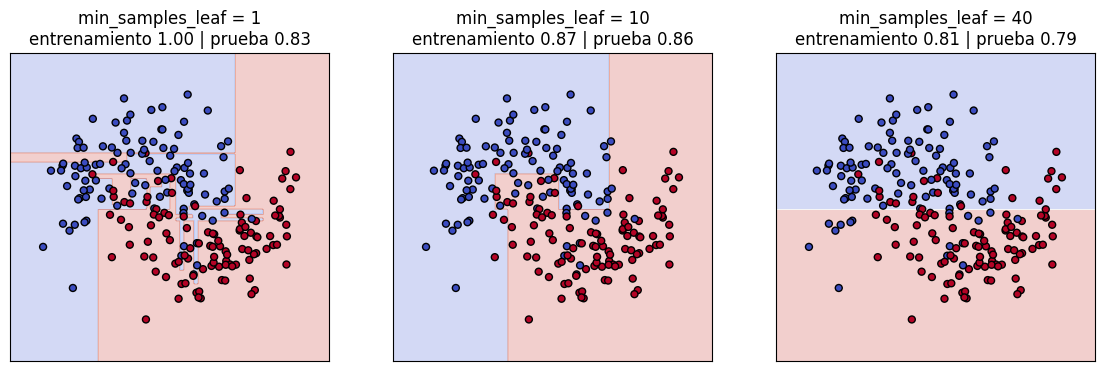

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, ms in zip(ejes, [1, 10, 40]):
    m = DecisionTreeClassifier(min_samples_leaf=ms, random_state=0)
    frontera(m, Xm_tr, ym_tr, ax, "")
    ax.set_title(f"min_samples_leaf = {ms}\nentrenamiento {m.score(Xm_tr, ym_tr):.2f} | prueba {m.score(Xm_te, ym_te):.2f}")
plt.show()

Con `1` es el mosaico loco; con `10` la frontera se suaviza; con `40` es demasiado burda. Este parámetro es **más fácil de entender para el negocio**: *"no me fío de una regla que se basa en menos de 10 clientes"*.

### Experimento D · Medir el efecto en los datos reales (tabla comparativa)

In [9]:
configs = {
    "Sin límites (memoriza)": dict(),
    "max_depth=3": dict(max_depth=3),
    "min_samples_leaf=20": dict(min_samples_leaf=20),
    "max_depth=4 + min_samples_leaf=20": dict(max_depth=4, min_samples_leaf=20),
    "max_depth=4 + leaf=20 + balanced": dict(max_depth=4, min_samples_leaf=20, class_weight="balanced"),
}
filas = {}
for nombre, params in configs.items():
    m = DecisionTreeClassifier(random_state=SEMILLA, **params).fit(Xp_tr, y_tr)
    r = metricas(m, Xp_val, y_val)
    r["AUC entrenamiento"] = round(roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]), 3)
    r["hojas"] = m.get_n_leaves()
    filas[nombre] = r
pd.DataFrame(filas).T

,exactitud,precisión,recall,F1,AUC,AUC entrenamiento,hojas
Sin límites (memoriza),0.693,0.467,0.488,0.477,0.632,1.000,159.0
max_depth=3,0.770,0.793,0.267,0.400,0.759,0.779,8.0
min_samples_leaf=20,0.747,0.561,0.535,0.548,0.740,0.860,32.0
max_depth=4 + min_samples_leaf=20,0.767,0.682,0.349,0.462,0.767,0.808,13.0
max_depth=4 + leaf=20 + balanced,0.660,0.447,0.791,0.571,0.756,0.818,15.0


**Lectura:** el árbol sin límites tiene un **AUC de entrenamiento = 1,0** y 159 hojas, pero en validación saca solo ~0,63 (el peor de la tabla). Los árboles "frenados" tienen menos hojas, una nota de validación **mejor y más estable**. Con `class_weight="balanced"` sube el **recall**.

### Experimento E · Poda con `ccp_alpha`
La **poda** es construir un árbol grande y luego cortar las ramas que aportan poco. `ccp_alpha` es cuánto "castigo" aplicamos por cada hoja extra.

In [10]:
alphas = [0, 0.0005, 0.001, 0.003, 0.01, 0.03]
filas = []
for a in alphas:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=SEMILLA).fit(Xp_tr, y_tr)
    filas.append({"ccp_alpha": a, "hojas": m.get_n_leaves(),
                  "AUC entrenamiento": roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Xp_val)[:, 1])})
pd.DataFrame(filas).round(3)

,ccp_alpha,hojas,AUC entrenamiento,AUC validación
0,0.000,159,1.000,0.632
1,0.000,159,1.000,0.632
2,0.001,157,1.000,0.633
3,0.003,33,0.889,0.703
4,0.010,4,0.752,0.753
5,0.030,2,0.680,0.673


A mayor `ccp_alpha`, menos hojas (árbol más simple). Si es demasiado alto, el árbol queda tan podado que pierde capacidad.

## 4. ¿Qué variables usa el árbol? (`feature_importances_`)
El árbol mide cuánta impureza redujo cada variable en todo el árbol. Las que más redujeron son las más importantes.

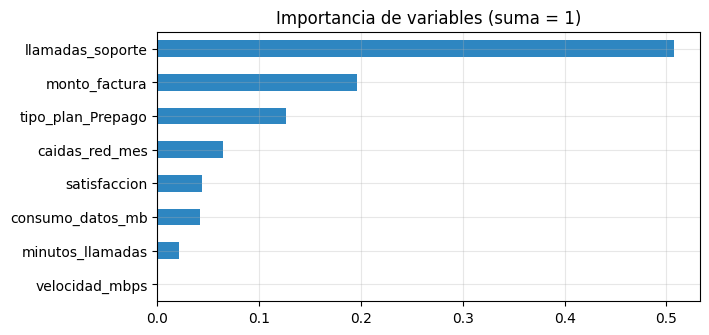

llamadas_soporte     0.508
monto_factura        0.196
tipo_plan_Prepago    0.126
caidas_red_mes       0.064
satisfaccion         0.043
consumo_datos_mb     0.042
minutos_llamadas     0.021
velocidad_mbps       0.000
dtype: float64

In [11]:
buen_arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEMILLA).fit(Xp_tr, y_tr)
imp = pd.Series(buen_arbol.feature_importances_, index=nombres).sort_values(ascending=False).head(8)

imp[::-1].plot.barh(color="#2e86c1", figsize=(7, 3.5))
plt.title("Importancia de variables (suma = 1)"); plt.show()
imp.round(3)

> **Cuidado al interpretar:** la importancia dice qué variable *ayudó al árbol a cortar*, **no** que *cause* que el cliente se vaya. Sirve para priorizar qué mirar, no para afirmar causas.

## 5. Árboles para predecir números (`DecisionTreeRegressor`)
También sirven para regresión: en cada hoja predicen **el promedio** de los clientes que cayeron ahí. El resultado es una función "en escalones".

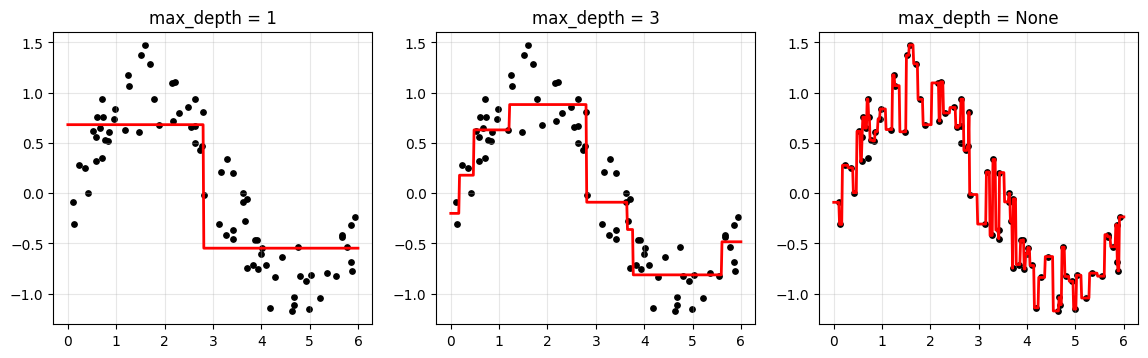

In [12]:
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0, 6, 80)); y = np.sin(x) + rng.normal(0, 0.25, 80)
xs = np.linspace(0, 6, 400).reshape(-1, 1)

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, d in zip(ejes, [1, 3, None]):
    r = DecisionTreeRegressor(max_depth=d, random_state=0).fit(x.reshape(-1, 1), y)
    ax.scatter(x, y, s=15, color="k"); ax.plot(xs, r.predict(xs), "r", lw=2)
    ax.set_title(f"max_depth = {d}")
plt.show()

Profundidad 1 = un solo escalón (muy simple). Profundidad 3 = sigue la onda. Sin límite = un escalón por cada punto (se aprende el ruido).

## 6. De un árbol a un bosque aleatorio (Random Forest)
Un árbol solo es inestable: si cambias un poco los datos, el árbol cambia mucho. La solución: **entrenar muchos árboles distintos y que voten** (como preguntar la opinión a 200 personas en lugar de a una). Cada árbol ve una muestra distinta de clientes y un subconjunto de variables (`max_features`). Así los errores individuales se compensan.

| Parámetro de `RandomForestClassifier` | Qué hace | Consejo |
|---|---|---|
| `n_estimators` | Cuántos árboles votan | 100–500. Más árboles = más estable (sin riesgo de overfitting), pero más lento. |
| `max_depth`, `min_samples_leaf` | Igual que en un árbol | Para árboles individuales. |
| `max_features` | Variables que ve cada árbol en cada corte | `"sqrt"` (por defecto) suele ir muy bien. |
| `class_weight` | Peso por clase | `"balanced"` para clases desbalanceadas. |
| `n_jobs=-1` | Usar todos los núcleos | Acelera el entrenamiento. |

In [13]:
from sklearn.ensemble import RandomForestClassifier

comparacion = {
    "1 árbol sin límites": DecisionTreeClassifier(random_state=SEMILLA),
    "1 árbol (profundidad 4, hoja 20)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEMILLA),
    "Bosque de 200 árboles": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1),
}
tabla = {}
for nombre, m in comparacion.items():
    m.fit(Xp_tr, y_tr)
    tabla[nombre] = metricas(m, Xp_val, y_val)
pd.DataFrame(tabla).T

,exactitud,precisión,recall,F1,AUC
1 árbol sin límites,0.693,0.467,0.488,0.477,0.632
"1 árbol (profundidad 4, hoja 20)",0.767,0.682,0.349,0.462,0.767
Bosque de 200 árboles,0.777,0.732,0.349,0.472,0.799


El bosque suele ganar al árbol individual en AUC y es mucho más estable. **Costo:** pierde la facilidad de lectura (200 árboles no se leen). En el cuaderno de **Boosting** verás otra forma de combinar árboles, aún más potente.

## 7. Resumen: ¿qué mover y cuándo?
| Síntoma que ves | Qué probar |
|---|---|
| Entrenamiento ≈ 1,0 y validación mucho menor (**overfitting**) | Bajar `max_depth`; subir `min_samples_leaf` o `min_samples_split`; subir `ccp_alpha`; usar un bosque. |
| Ambas notas bajas (**underfitting**) | Subir `max_depth`; bajar `min_samples_leaf`; agregar variables. |
| Pocos clientes detectados (recall bajo) | `class_weight="balanced"`; bajar el umbral. |
| El árbol cambia mucho si cambias los datos | Usar `RandomForest` o boosting. |

### Ventajas y límites
| ✅ Ventajas | ⚠️ Límites |
|---|---|
| Se explica como reglas "si… entonces…". | Se sobreajusta con facilidad si no se frena. |
| No necesita escalar variables ni relaciones lineales. | Inestable: pequeños cambios de datos → árbol distinto. |
| Capta interacciones entre variables solo. | Un árbol solo rara vez es el más preciso. |

## 8. Ejercicios
1. En el Experimento A, ¿para qué profundidad la nota de validación es máxima? ¿Y si cambias `random_state` a 7?
2. Prueba `criterion="entropy"` con `max_depth=4`: ¿cambia el AUC?
3. Combina `max_depth=6` con `min_samples_leaf=30` y compara con `max_depth=6` solo.
4. Entrena un bosque con `n_estimators=10` y luego con `500`. ¿Cuánto mejora el AUC?
5. Para tu Evidencia 3: copia las reglas (`export_text`) de tu mejor árbol y escribe en 3 líneas qué clientes tienen más riesgo de irse.